# Descriptive Analytics

<h3>Imports & Plotting Configuration</h3>

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Set default visualization styles
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)



<h3>Load Cleaned Dataset</h3>

In [2]:
data_path = '../data/processed/cleaned_reviews.csv'

if not os.path.exists(data_path):
    raise FileNotFoundError(f"Cleaned dataset not found at {data_path}. Please run notebooks/01_data_prep.ipynb first!")

df = pd.read_csv(data_path)
print(f"Dataset Loaded Successfully! Rows: {len(df):,}, Columns: {df.shape[1]}")
df.head()

Dataset Loaded Successfully! Rows: 34,627, Columns: 14


,product_id,product_name,brand,category,rating,review_text,title,recommended_raw,helpful_votes,recommended_ind,recommended_label,review_char_count,review_word_count,has_title
0,AVqkIhwDv8e3D1O-lebb,"All-New Fire HD 8 Tablet, 8 HD Display, Wi-Fi,...",Amazon,Electronics,5,This product so far has not disappointed. My c...,Kindle,True,0.0,1,Recommended,143,27,1
1,AVqkIhwDv8e3D1O-lebb,"All-New Fire HD 8 Tablet, 8 HD Display, Wi-Fi,...",Amazon,Electronics,5,great for beginner or experienced person. Boug...,very fast,True,0.0,1,Recommended,75,14,1
2,AVqkIhwDv8e3D1O-lebb,"All-New Fire HD 8 Tablet, 8 HD Display, Wi-Fi,...",Amazon,Electronics,5,Inexpensive tablet for him to use and learn on...,Beginner tablet for our 9 year old son.,True,0.0,1,Recommended,131,26,1
3,AVqkIhwDv8e3D1O-lebb,"All-New Fire HD 8 Tablet, 8 HD Display, Wi-Fi,...",Amazon,Electronics,4,I've had my Fire HD 8 two weeks now and I love...,Good!!!,True,0.0,1,Recommended,593,117,1
4,AVqkIhwDv8e3D1O-lebb,"All-New Fire HD 8 Tablet, 8 HD Display, Wi-Fi,...",Amazon,Electronics,5,I bought this for my grand daughter when she c...,Fantastic Tablet for kids,True,0.0,1,Recommended,613,117,1


<h3>Business KPIs Summary</h3>

In [3]:
total_reviews = len(df)
avg_rating = df['rating'].mean() 
recommendation_rate = (df['recommended_ind'].mean()) * 100
avg_word_count = df['review_word_count'].mean()
unique_products = df['product_id'].nunique() 

print("==================================================")
print("             EXECUTIVE KPI DASHBOARD              ")
print("==================================================")
print(f" Total Reviews Analyzed   : {total_reviews:,}")
print(f" Average Rating Score     : {avg_rating:.2f} / 5.0")
print(f" Overall Recommendation % : {recommendation_rate:.1f}%")
print(f" Unique Products   : {unique_products:,}")
print(f" Average Words per Review : {avg_word_count:.1f} words")
print("==================================================")

             EXECUTIVE KPI DASHBOARD              
 Total Reviews Analyzed   : 34,627
 Average Rating Score     : 4.58 / 5.0
 Overall Recommendation % : 95.7%
 Unique Products   : 39
 Average Words per Review : 30.2 words


<h3>Star Rating & Recommendation Distributions</h3>

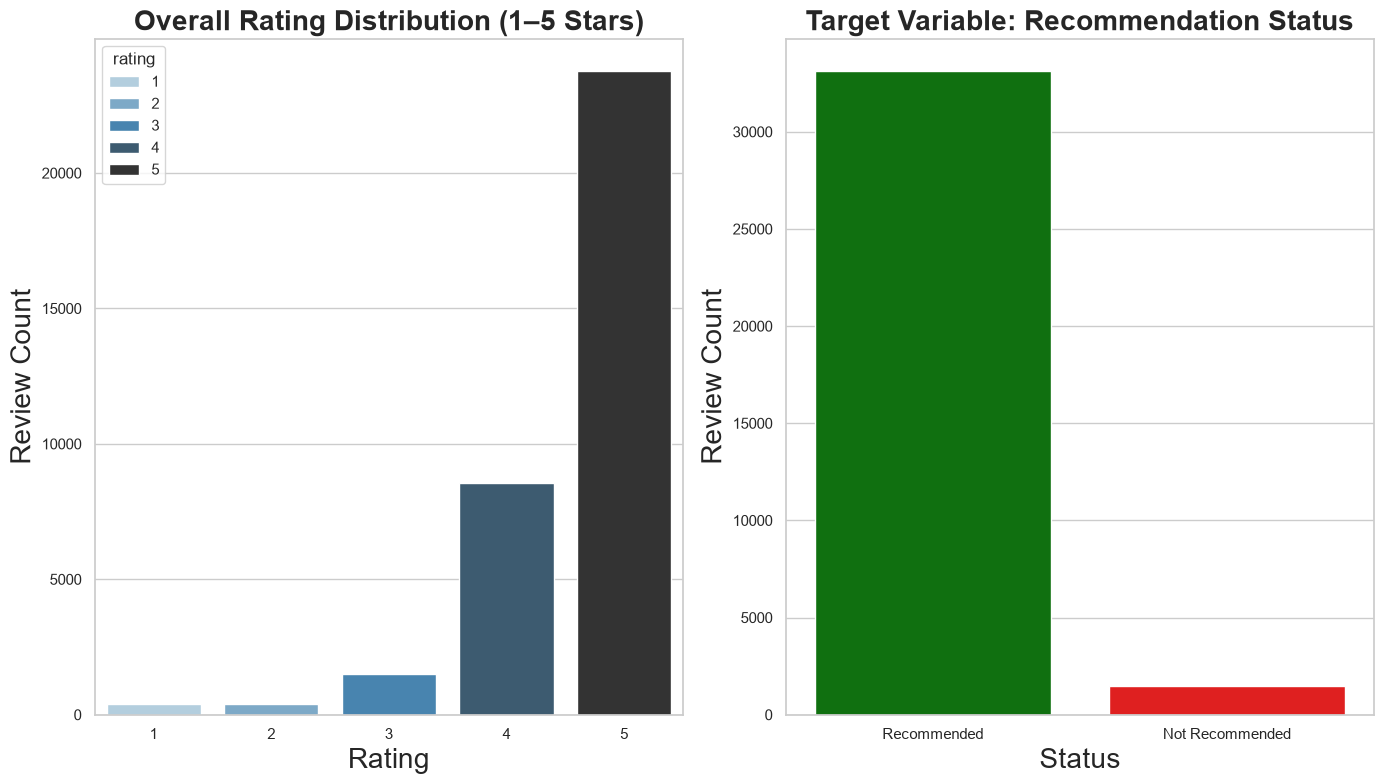

In [4]:
fig, axes = plt.subplots(1,2, figsize=(14, 8))

# Chart 1: Rating Distribution
sns.countplot(data=df, x='rating',hue='rating', palette='Blues_d', ax=axes[0])
axes[0].set_title('Overall Rating Distribution (1–5 Stars)', fontsize=20, fontweight='bold')
axes[0].set_xlabel('Rating', fontsize=20)
axes[0].set_ylabel('Review Count', fontsize=20)

# Chart 2: Target Variable Recommendation Breakdown
sns.countplot(data=df, x='recommended_label',hue = 'recommended_label', palette=['Green', 'Red'], ax=axes[1])
axes[1].set_title('Target Variable: Recommendation Status', fontsize=20, fontweight='bold')
axes[1].set_xlabel('Status', fontsize=20)
axes[1].set_ylabel('Review Count', fontsize=20)

plt.tight_layout()
plt.show()

<h3>Top Categories KPI Performance</h3>

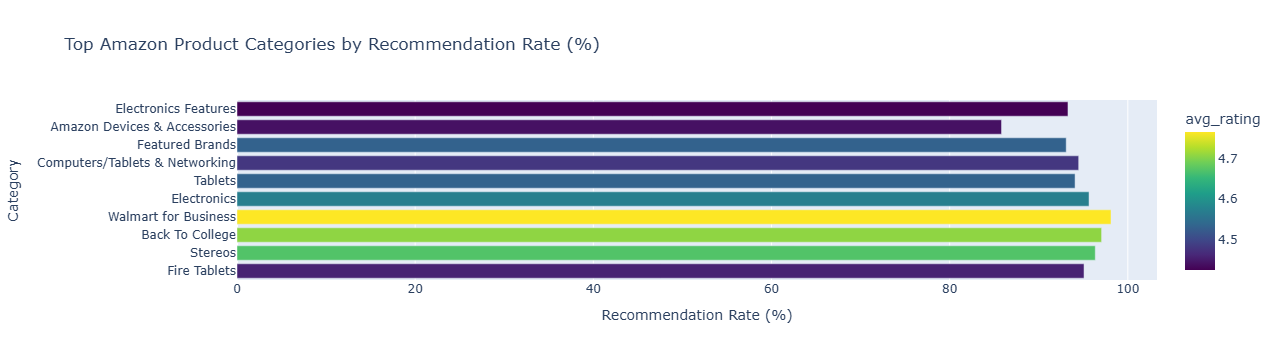

In [6]:
# Group by category and compute summary metrics
cat_summary = df.groupby('category').agg(
    total_reviews=('rating', 'count'),
    avg_rating=('rating', 'mean'),
    recommendation_rate=('recommended_ind', lambda x: x.mean() * 100),
    avg_words=('review_word_count', 'mean')
).reset_index()

# Filter top categories with at least 50 reviews
top_cats = cat_summary[cat_summary['total_reviews'] >= 50].sort_values(by='total_reviews', ascending=False)

# Interactive Plotly Horizontal Bar Chart
fig_cat = px.bar(
    top_cats.head(10),
    x='recommendation_rate',
    y='category',
    orientation='h',
    color='avg_rating',
    title='Top Amazon Product Categories by Recommendation Rate (%)',
    labels={'recommendation_rate': 'Recommendation Rate (%)', 'category': 'Category'},
    color_continuous_scale='Viridis'
)

fig_cat.show()

<h3>Review Length vs. Customer Satisfaction</h3>

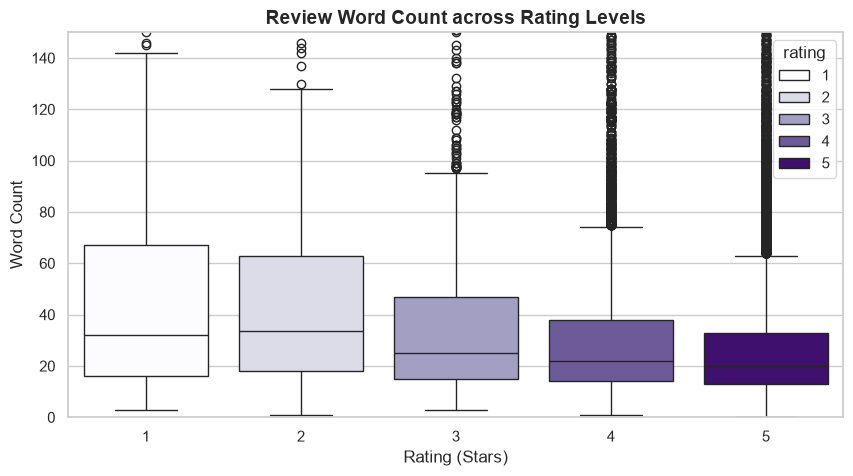

In [13]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='rating', y='review_word_count',hue='rating', palette='Purples')
plt.title('Review Word Count across Rating Levels', fontsize=14, fontweight='bold')
plt.xlabel('Rating (Stars)')
plt.ylabel('Word Count')
plt.ylim(0, 150)  # Capped for clearer visual comparison
plt.show()